# 1. Coletar dados

### 1.1 Carregar a rede

In [2]:
import networkx as nx
import pandas as pd
import random

caminho = "./data/facebook_combined.txt.gz"

In [3]:
G = nx.read_edgelist(
    caminho,
    nodetype=int
)

print("Nós:", G.number_of_nodes())
print("Arestas:", G.number_of_edges())

Nós: 4039
Arestas: 88234


### 1.2 Escolher os 404 nós aleatórios

In [4]:
# Definindo semente fixa de 42 para que a mesma amostra 
# aleatória seja gerada sempre para nossas análises
rng = random.Random(42)

# selecionar 404 usuários aleatoriamente e extrair todas as arestas incidentes a esses usuários, 
# inclusive as conexões com usuários que não foram sorteados
nos_selecionados = rng.sample(list(G.nodes()), 404)
# print("Lista de nós selecionados:", nos_selecionados)



# 2. Construir o grafo

### 2.1 Representar a rede com NetworkX

In [29]:
# OPÇÃO 1:
#  Se for para ter exatamente 404 nós e manter só as arestas que conectam os sorteados, precisa:
G_amostra = G.subgraph(nos_selecionados).copy()
print("Nós:", G_amostra.number_of_nodes())
print("Arestas:", G_amostra.number_of_edges())

# OPÇÃO 2:
# Se for para extrair todas as arestas incidentes aos nós selecionados, e consequentemente 
# adicionar os nós aos quais os nós selecionados se conectam:
# arestas_selecionadas = [
#     (u, v)
#     for u, v in G.edges()
#     if u in nos_selecionados or v in nos_selecionados
# ]

# G_amostra = nx.Graph()
# G_amostra.add_edges_from(arestas_selecionadas)
# print("Nós adicionados devido as conexões:", G_amostra.number_of_nodes())
# print("Todas as arestas conectadas aos 404 nós escolhidos:", G_amostra.number_of_edges())

Nós: 404
Arestas: 727


### 2.2 Visualizar o grafo gerado

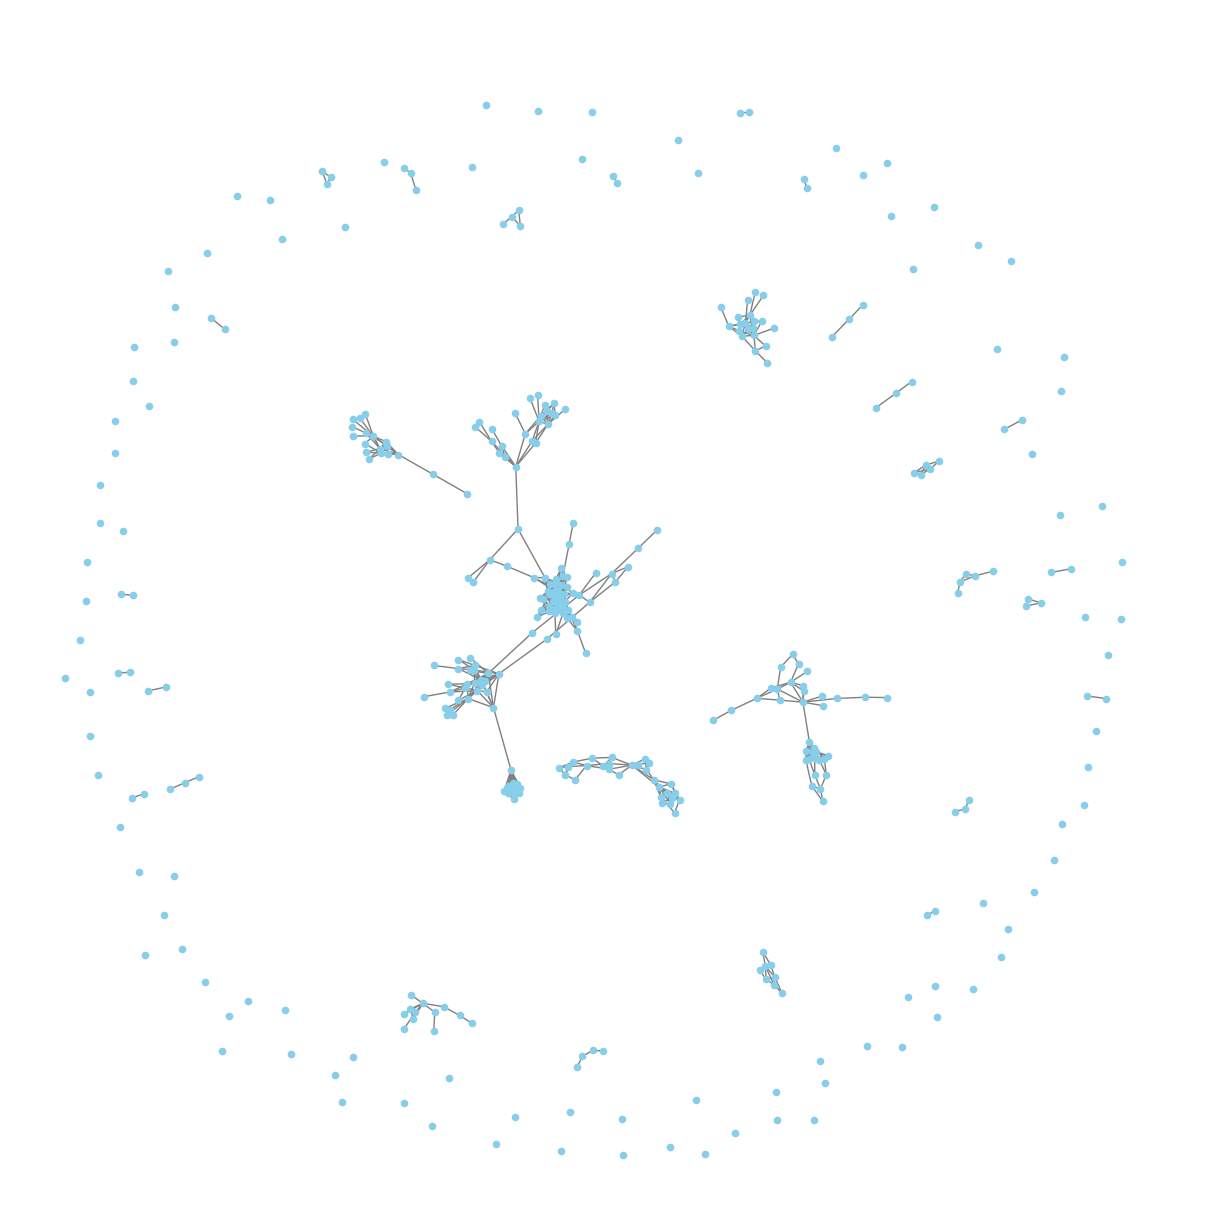

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))

# pos = associa cada nó a uma posição no desenho
# seed=42 ajuda a manter a mesma disposição dos itens no desenho executar novamente
pos = nx.spring_layout(G_amostra, seed=42) 

nx.draw(
    G_amostra,
    pos,
    node_size=20,
    node_color="skyblue",
    edge_color="gray",
    with_labels=False
)

plt.show()

# 3. Calcular métricas

## 3.1 Mapear comunidades pelo algoritmo de Louvain

In [31]:
## Louvain = identificar grupos de nós que têm mais conexões entre si do que com o resto da rede
comunidades = nx.community.louvain_communities(G_amostra, seed=42)

# Retorna uma lista, em que cada item é um comunidade
print("Lista de comunidades: ", comunidades)
# todo: armazenar a lista de comunidades numa tabela do pandas
print("Quantidade de comunidades:", len(comunidades))

Lista de comunidades:  [{2, 326}, {8}, {2433, 2244, 1979, 2122, 2542, 2190, 1938, 2579, 2549, 2069, 2423, 2165, 2299, 2559}, {29}, {2079}, {47}, {2120, 1933}, {2049, 2146, 2342, 2503, 2570, 2411, 1975, 1978, 2301, 2175}, {102}, {2168}, {177, 131, 86}, {187}, {192}, {229}, {237}, {240}, {241}, {128, 322, 130, 260, 13, 79, 271, 207, 276, 26, 284, 221, 290, 108, 308, 248, 122, 60}, {262}, {283}, {292}, {361, 481}, {365}, {2422}, {386}, {2470}, {443}, {2496}, {476}, {498}, {518}, {2613}, {2176, 2241, 2498, 1987, 1994, 2445, 2511, 2259, 2325, 2390, 2264, 2652, 2589, 2207, 2208, 2017, 2296, 2215, 2026, 2283, 2415, 2608, 2230, 2616, 2425, 2298, 2110}, {586}, {1921, 1927, 1998, 2159, 2097, 2645, 2620, 2494}, {628}, {2697}, {650}, {652}, {2686, 2702}, {2722}, {673}, {679}, {680, 611}, {692}, {736, 772, 712, 713, 844, 845, 748, 718, 694, 856, 734, 767}, {704}, {3076, 3015, 3274, 2829, 3215, 2768, 3093, 3287, 3162, 2845, 2849, 3171, 3367, 3118, 2672, 3312, 3378, 2935, 2936}, {2791}, {2795}, {749}

### 3.2 Calcular as medidas de centralidade

In [32]:

## Grau: quantas conexões um nó possui, normalizadas pelo tamanho do grafo.
grau = nx.degree_centrality(G_amostra)
print("Graus de todos os nós selecionados: ", grau)


Graus de todos os nós selecionados:  {2049: 0.012406947890818858, 2: 0.0024813895781637717, 8: 0.0, 13: 0.004962779156327543, 2069: 0.024813895781637715, 26: 0.022332506203473945, 29: 0.0, 2079: 0.0, 47: 0.0, 2097: 0.009925558312655087, 60: 0.0024813895781637717, 2110: 0.009925558312655087, 2120: 0.0024813895781637717, 2122: 0.02729528535980149, 79: 0.004962779156327543, 86: 0.0024813895781637717, 2146: 0.0024813895781637717, 102: 0.0, 108: 0.0024813895781637717, 2159: 0.009925558312655087, 2165: 0.024813895781637715, 2168: 0.0, 122: 0.017369727047146403, 2175: 0.004962779156327543, 2176: 0.022332506203473945, 128: 0.012406947890818858, 130: 0.0024813895781637717, 131: 0.0024813895781637717, 2190: 0.03225806451612903, 2207: 0.0024813895781637717, 2208: 0.004962779156327543, 2215: 0.01488833746898263, 177: 0.004962779156327543, 2230: 0.0024813895781637717, 187: 0.0, 192: 0.0, 2241: 0.017369727047146403, 2244: 0.02977667493796526, 207: 0.0024813895781637717, 2259: 0.009925558312655087, 2

In [33]:

# Intermediação: quanto um nó participa dos caminhos mínimos entre outros nós.
intermediacao = nx.betweenness_centrality(G_amostra)
print("Intermediação:", intermediacao)

Intermediação: {2049: 0.0016693091319956983, 2: 0.0, 8: 0.0, 13: 0.0, 2069: 9.343088303126818e-06, 26: 0.0002829113325020884, 29: 0.0, 2079: 0.0, 47: 0.0, 2097: 1.5225773531021484e-05, 60: 0.0, 2110: 0.0, 2120: 0.0, 2122: 5.464319378618841e-05, 79: 0.0, 86: 0.0, 2146: 0.0, 102: 0.0, 108: 0.0, 2159: 2.3044413992897382e-05, 2165: 8.108566124935887e-06, 2168: 0.0, 122: 0.0004125361612121361, 2175: 0.0018984305695908964, 2176: 0.002958414826493787, 128: 3.292059141842482e-05, 130: 0.0, 131: 0.0, 2190: 6.350529942248757e-05, 2207: 0.0, 2208: 5.658226650041767e-06, 2215: 0.00047562906253325124, 177: 1.2345221781909311e-05, 2230: 0.0, 187: 0.0, 192: 0.0, 2241: 0.00018207732459056482, 2244: 6.083985381048443e-05, 207: 0.0, 2259: 0.0006145862910427187, 2264: 0.00027958987997505084, 221: 0.0, 229: 0.0, 2283: 0.0038217573364419774, 237: 0.0, 240: 0.0, 241: 0.0, 2288: 0.0, 248: 0.0, 2296: 0.0006049158673135563, 2298: 0.0, 2299: 0.00595190175113141, 2301: 0.0, 260: 0.0, 262: 0.0, 271: 0.00021295507

In [34]:
# Proximidade: quão perto um nó está dos demais, considerando os caminhos mínimos.
proximidade = nx.closeness_centrality(G_amostra)
print("Proximidade:")

Proximidade:


In [35]:
# considera não apenas quantas conexões um nó tem, mas também a importância dos nós aos quais está conectado.
autovetor = nx.eigenvector_centrality(
    G_amostra,
    max_iter=1000
)

In [36]:

# Função auxiliar para identificar a qual comunidade cada nó pertence
comunidade_por_no = {
    no: i
    for i, comunidade in enumerate(comunidades)
    for no in comunidade
}


In [49]:

# Adicionar as métricas como atributos dos nós
nx.set_node_attributes(G_amostra, comunidade_por_no, "comunidade")
nx.set_node_attributes(G_amostra, grau, "grau")
nx.set_node_attributes(G_amostra, intermediacao, "intermediacao")
nx.set_node_attributes(G_amostra, proximidade, "proximidade")
nx.set_node_attributes(G_amostra, autovetor, "autovetor")

# Exportar o grafo para o Gephi
nx.write_gexf(G_amostra, "./data/grafo_metricas.gexf")


In [37]:

# Transforma todas as métricas extraídas em formato de Dataframe e salva em um csv 
df_metricas = pd.DataFrame({
    "no": list(G_amostra.nodes()),
    "comunidade": [
        comunidade_por_no[no]
        for no in G_amostra.nodes()
    ],
    "grau": [
        grau[no]
        for no in G_amostra.nodes()
    ],
    "intermediacao": [
        intermediacao[no]
        for no in G_amostra.nodes()
    ],
    "proximidade": [
        proximidade[no]
        for no in G_amostra.nodes()
    ],
    "autovetor": [
        autovetor[no]
        for no in G_amostra.nodes()
    ]
})

df_metricas.head()


df_metricas.to_csv(
    "./data/metricas_grafo.csv",
    index=False
)



# 4. Visualizar as medidas de forma explícita

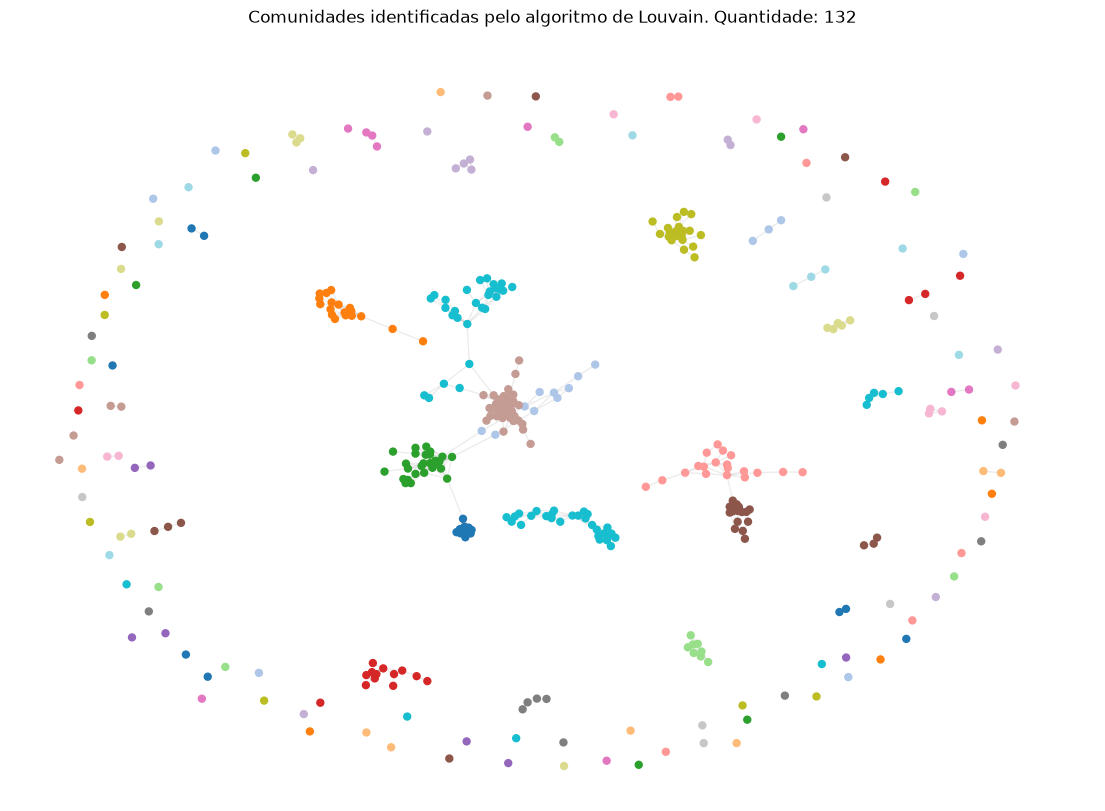

In [ ]:

# Visualizar as comunidades de Louvain geradas, cada uma com uma cor diferente
cores_comunidades = [
    comunidade_por_no[no]
    for no in G_amostra.nodes()
]

plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    G_amostra, pos,
    alpha=0.15,
    edge_color="gray"
)

nx.draw_networkx_nodes(
    G_amostra, pos,
    node_color=cores_comunidades,
    cmap=plt.cm.tab20,
    node_size=25
)

plt.title(f'Comunidades identificadas pelo algoritmo de Louvain. Quantidade: {len(comunidades)}')
plt.axis("off")
plt.show()

In [62]:
# Função auxiliar para visualizar as medidas de centralidade

def visualizar_centralidade(G, pos, metricas, nome_metrica, top_k=10):
    maiores = sorted(
        metricas.items(),
        key=lambda item: item[1],
        reverse=True
    )[:top_k]

    valores = [metricas[no] for no in G.nodes()]
    nos_destacados = [no for no, valor in maiores]

    plt.figure(figsize=(18, 14))

    nx.draw_networkx_edges(
        G, pos,
        alpha=0.08,
        edge_color="gray"
    )

    nos = nx.draw_networkx_nodes(
        G, pos,
        node_color=valores,
        cmap=plt.cm.plasma,
        node_size=25
    )

    # Desenha os nós mais importantes por cima dos demais
    nx.draw_networkx_nodes(
        G, pos,
        nodelist=nos_destacados,
        node_color="red",
        node_size=180,
        edgecolors="black"
    )

    rotulos = {
        no: f"{no}\n{metricas[no]:.4f}"
        for no in nos_destacados
    }

# Para retirar labels só comentar esse pedaço. As labels podem ficar confusas dependendo da img
    nx.draw_networkx_labels(
        G, pos,
        labels=rotulos,
        font_size=10,
        font_weight="bold",
        bbox={
            "facecolor": "white",
            "edgecolor": "gray",
            "alpha": 0.9,
            "pad": 2
        }
    )

    plt.colorbar(nos, label=f"Centralidade: {nome_metrica}")
    plt.title(f"{nome_metrica} — Top {top_k} nós")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return maiores


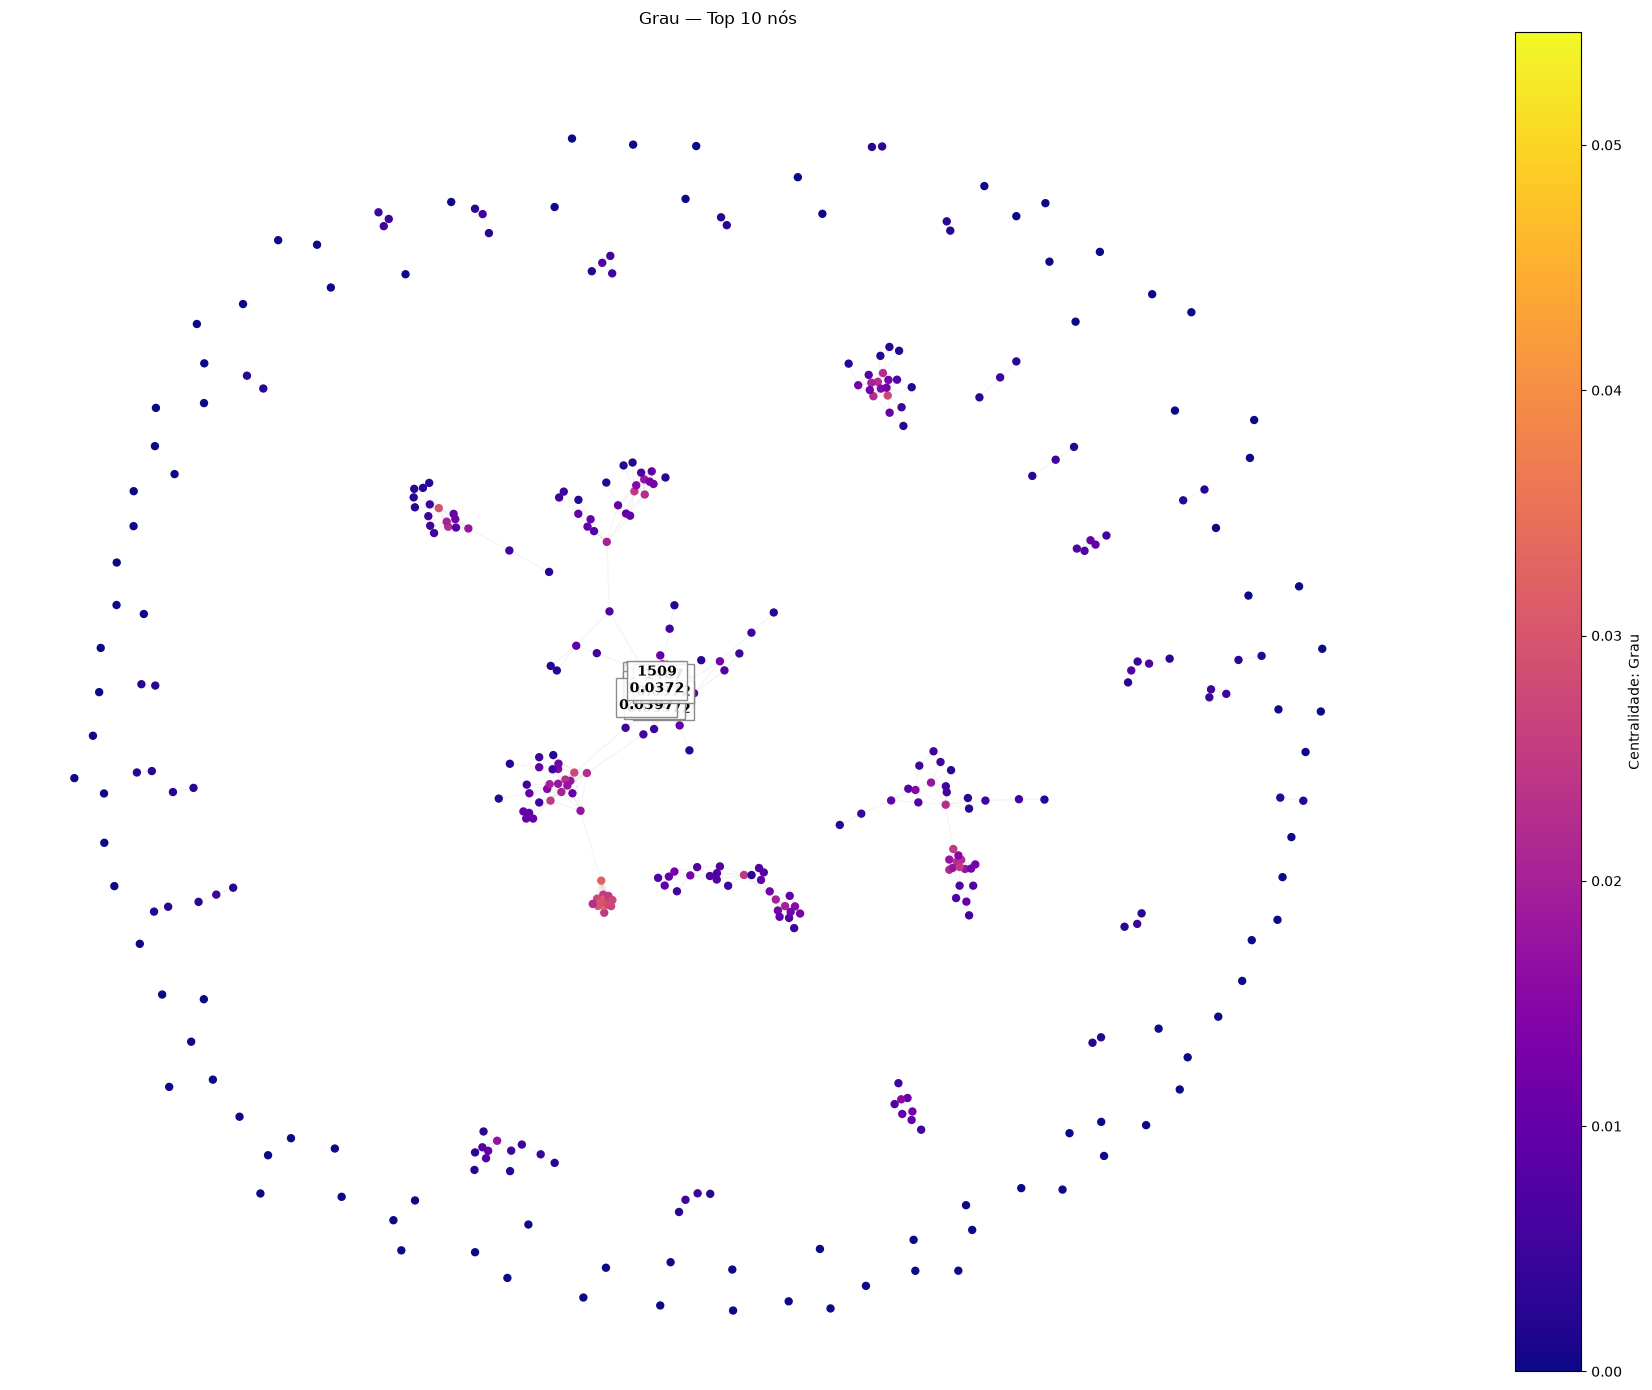

In [63]:
top_grau = visualizar_centralidade(
    G_amostra, pos, grau, "Grau"
)

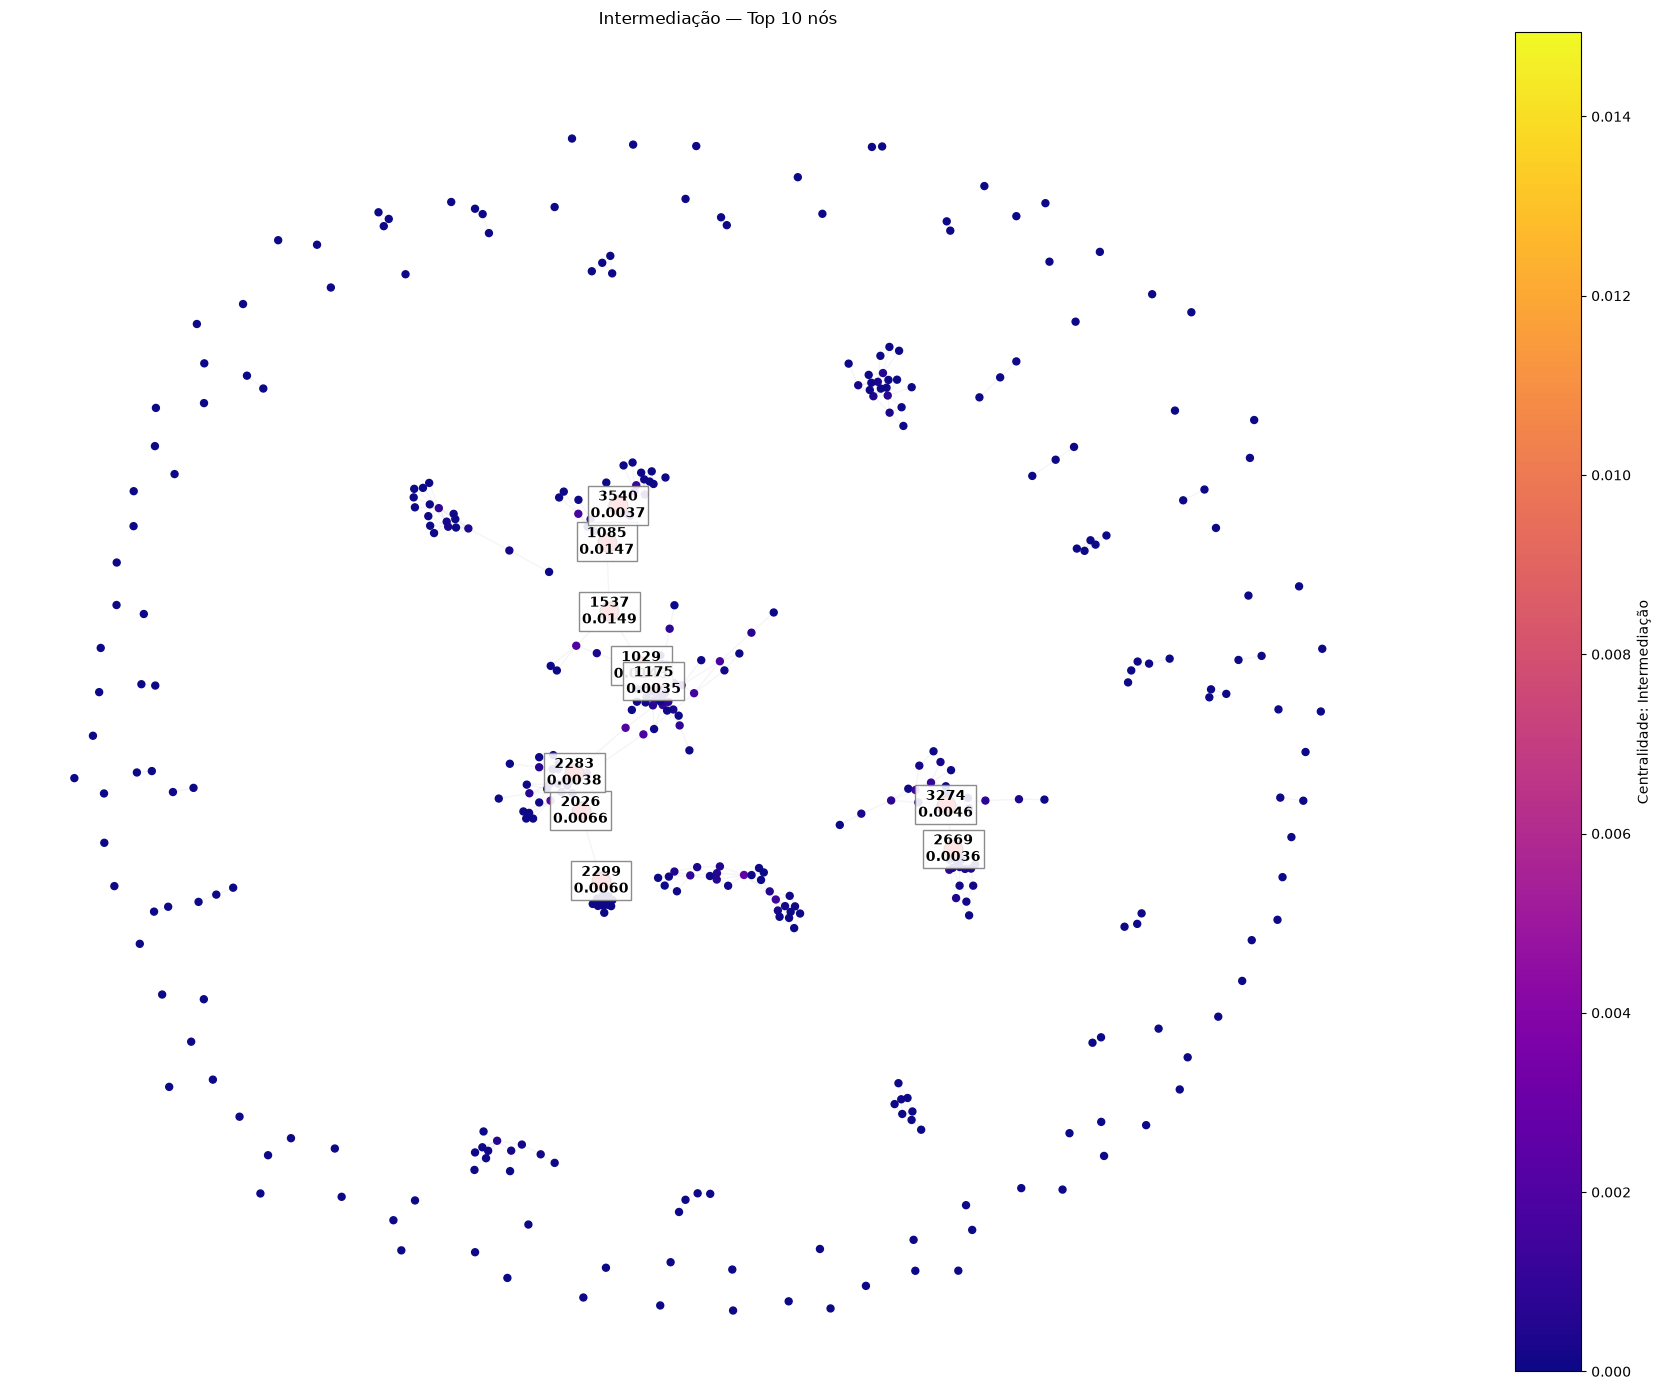

In [64]:
top_intermediacao = visualizar_centralidade(
    G_amostra, pos, intermediacao, "Intermediação"
)

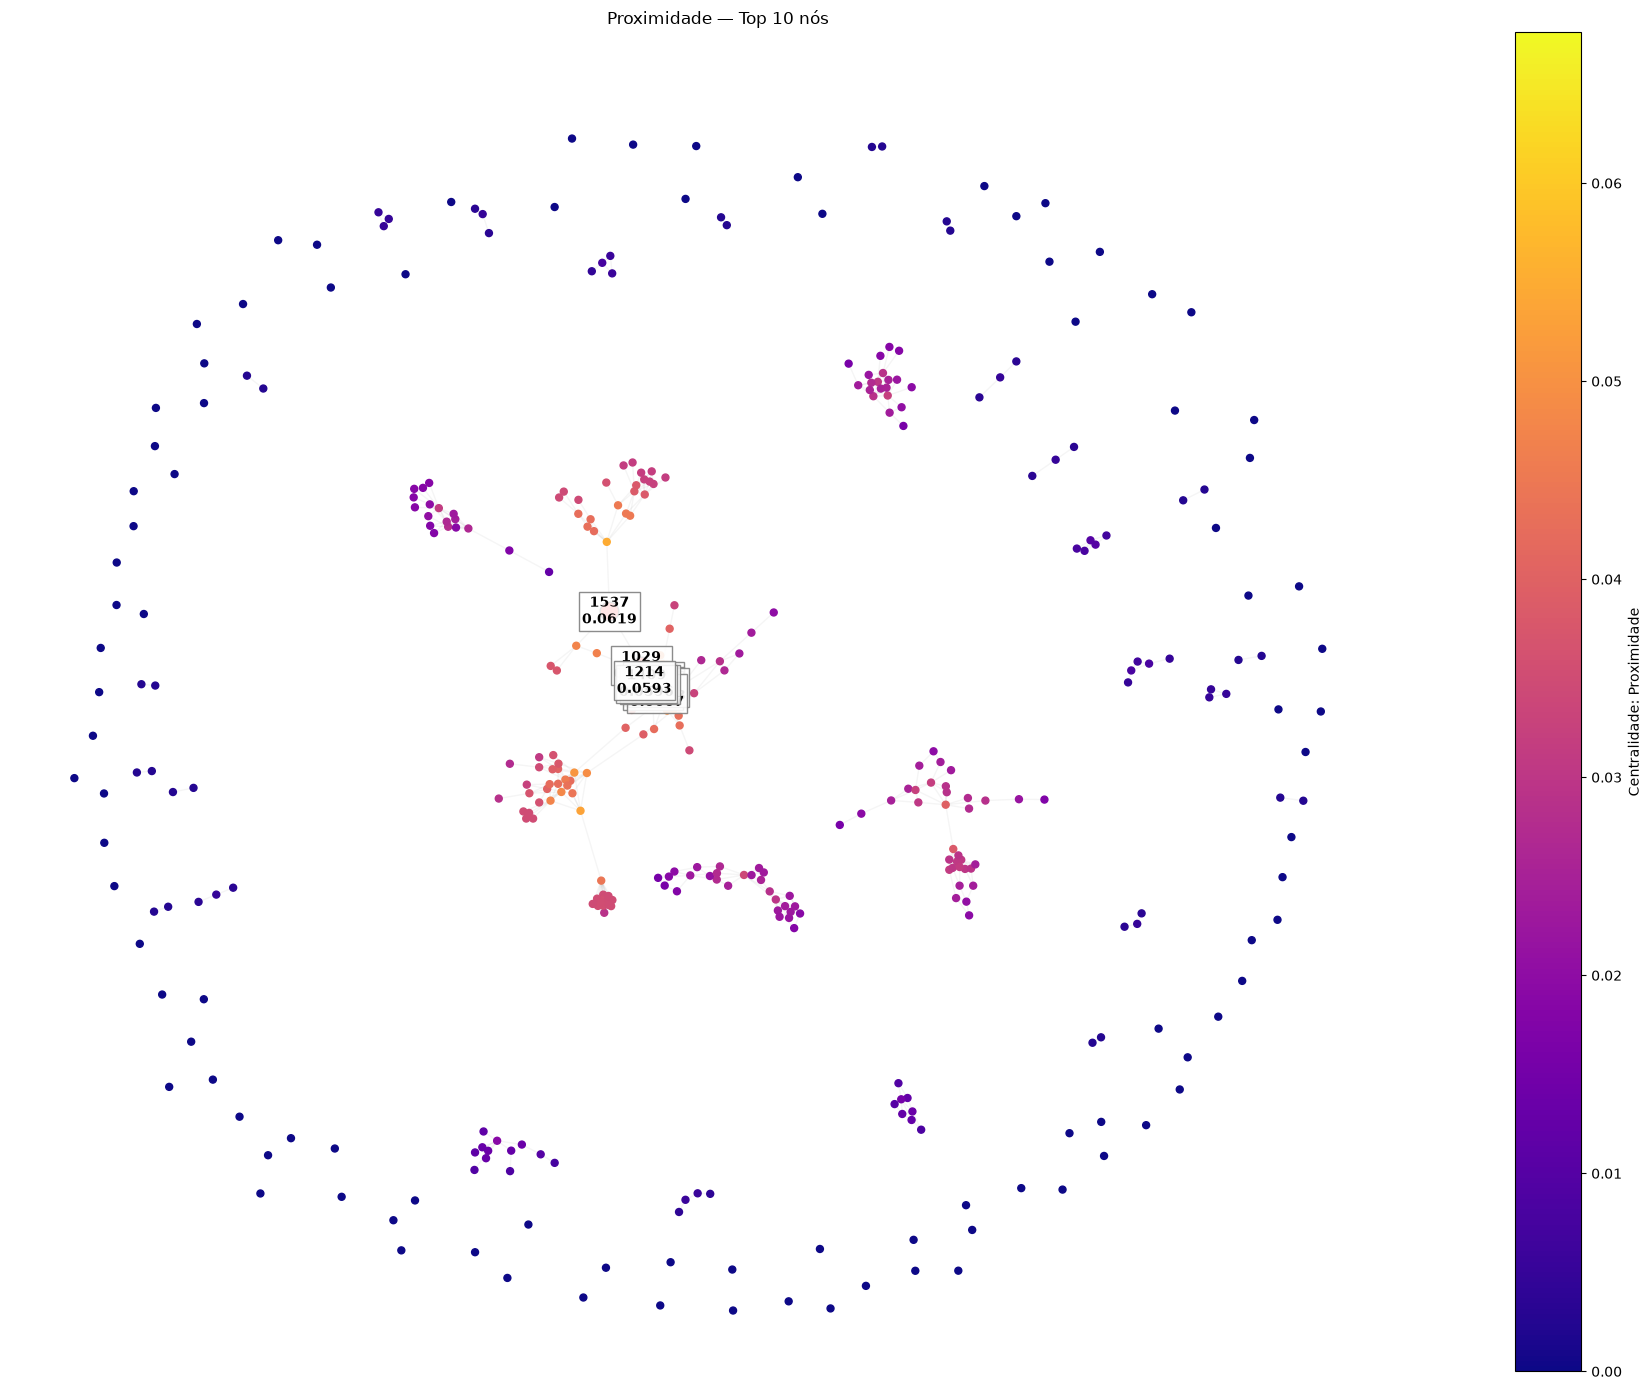

In [53]:
top_proximidade = visualizar_centralidade(
    G_amostra, pos, proximidade, "Proximidade"
)

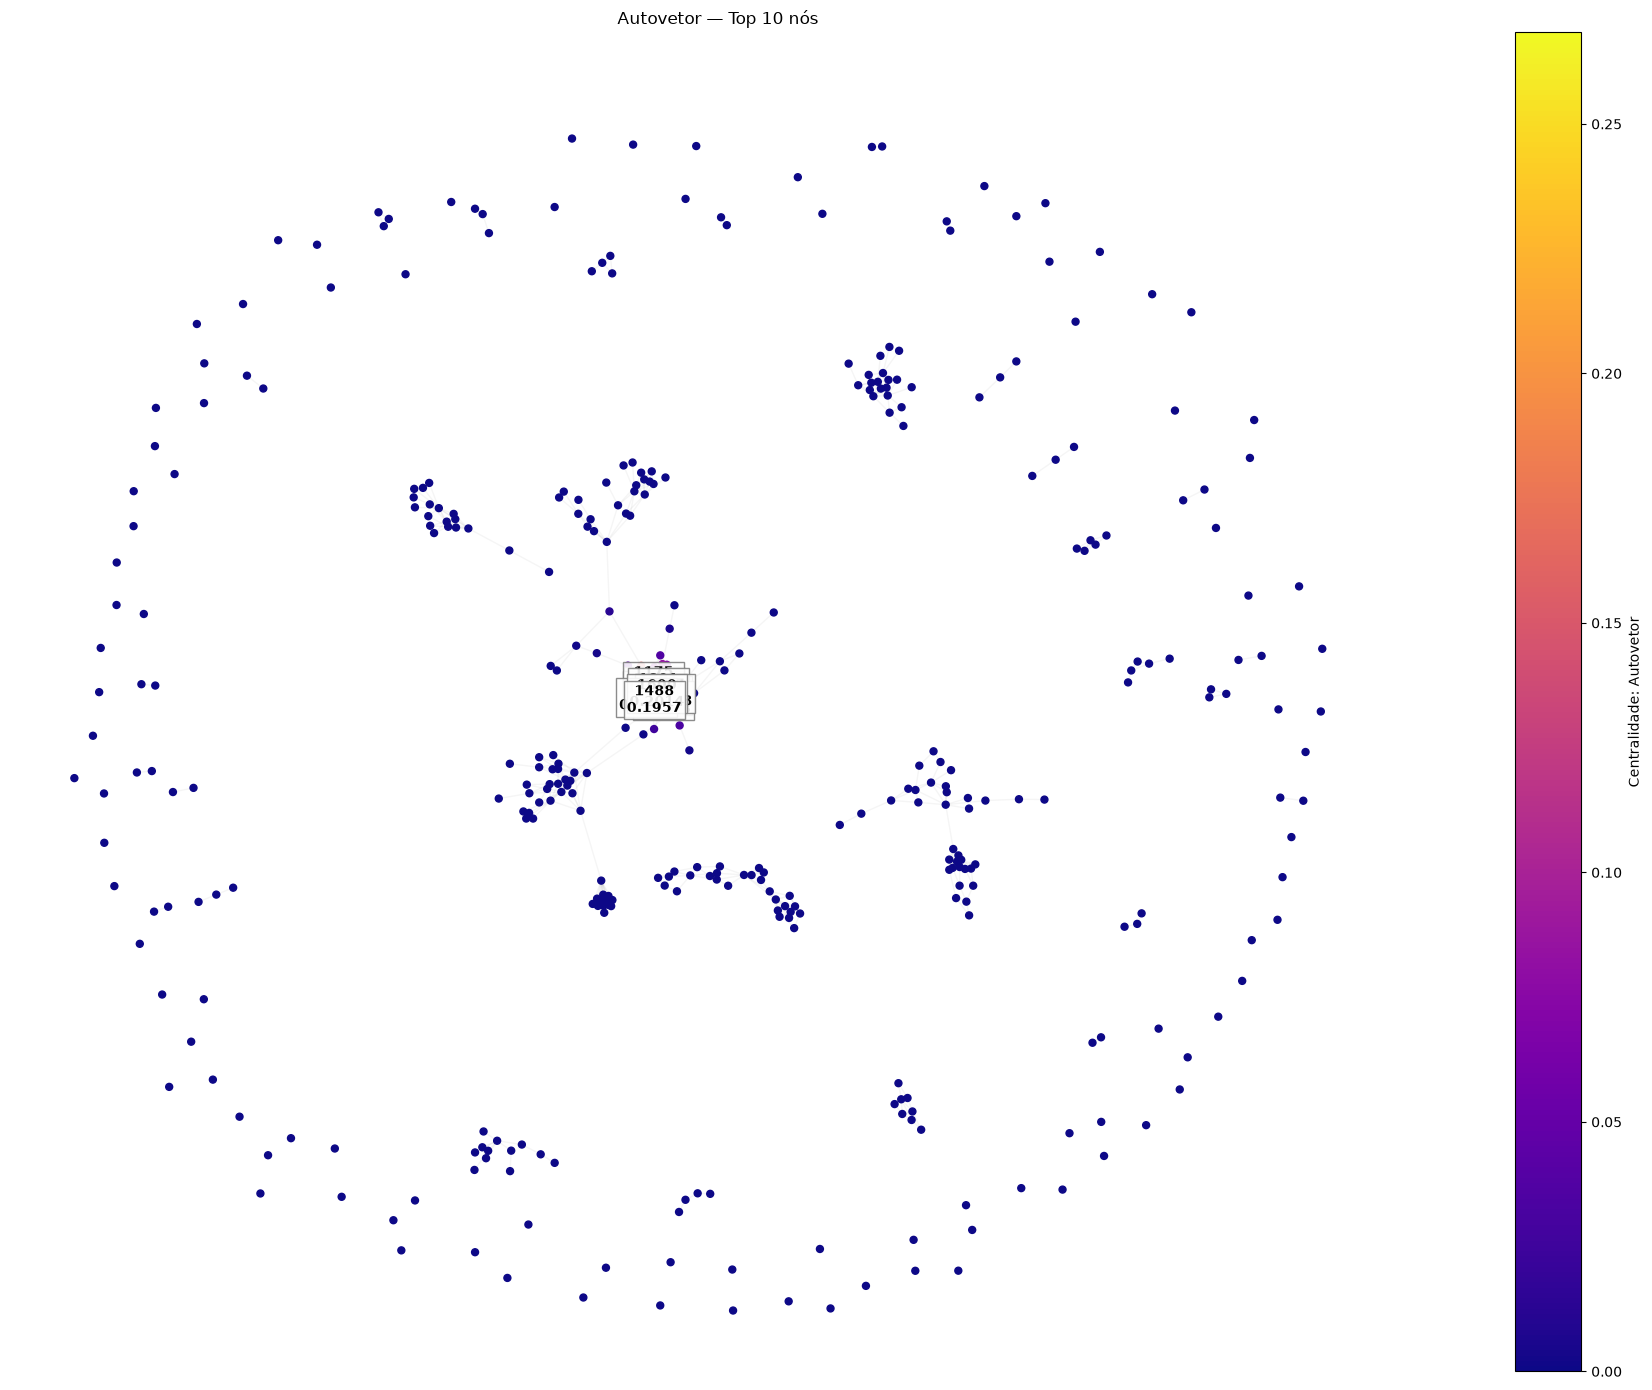

In [54]:
top_autovetor = visualizar_centralidade(
    G_amostra, pos, autovetor, "Autovetor"
)

### 4.1 Visualizar os grafos no navegador com pyvis

In [77]:

# Gera um grafo interativo da rede base criada para ser visto no navegador
from pyvis.network import Network

grafo_visual = Network(
    height="750px",
    width="100%",
    bgcolor="white",
    font_color="black",
    notebook=True,
    cdn_resources="in_line"
)

# Adicionar nós e arestas do NetworkX
grafo_visual.from_nx(G_amostra)

# # Mostrar o grafo interativo
grafo_visual.write_html("./data/metricas/rede_gerada.html")


In [ ]:
# Função auxiliar que recebe uma métrica, seleciona os 10 nós
# com maiores valores e gera um HTML interativo

from pyvis.network import Network
from pathlib import Path
import colorsys

# Pasta em que os arquivos HTML serão salvos
pasta_saida = Path("./data/metricas")
pasta_saida.mkdir(parents=True, exist_ok=True)


def visualizar_metrica(G, metricas, nome_metrica, top_k=10):
    # Selecionar os nós com os maiores valores
    maiores = sorted(
        metricas.items(),
        key=lambda item: item[1],
        reverse=True
    )[:top_k]

    nos_destacados = {no for no, valor in maiores}

    menor = min(metricas.values())
    maior = max(metricas.values())

    grafo_visual = Network(
        height="800px",
        width="100%",
        bgcolor="white",
        font_color="black",
        cdn_resources="in_line"
    )

    # Adicionar os nós
    for no in G.nodes():
        valor = metricas[no]

        if maior > menor:
            proporcao = (valor - menor) / (maior - menor)
        else:
            proporcao = 0.5

        # Cor varia conforme o valor da métrica
        cor = colorsys.hsv_to_rgb(
            0.7 * (1 - proporcao), 0.85, 0.95
        )
        cor = "#{:02x}{:02x}{:02x}".format(
            int(cor[0] * 255),
            int(cor[1] * 255),
            int(cor[2] * 255)
        )

        # Destacar os nós com maiores valores
        destaque = no in nos_destacados

        rotulo = (
            f"{no}\n{valor:.4f}"
            if destaque
            else str(no)
        )

        grafo_visual.add_node(
            no,
            label=rotulo,
            title=f"Nó: {no}<br>{nome_metrica}: {valor:.6f}",
            color="red" if destaque else cor,
            size=30 if destaque else 10,
            font={"size": 18 if destaque else 10}
        )

    # Adicionar as arestas
    grafo_visual.add_edges(G.edges())

    # Salvar o arquivo HTML
    nome_arquivo = (
        nome_metrica.lower()
        .replace(" ", "_")
        .replace("ã", "a")
        .replace("ç", "c")
    )

    caminho = pasta_saida / f"{nome_arquivo}.html"

    grafo_visual.write_html(str(caminho))

    print(f"Arquivo gerado: {caminho}")

    return maiores


## 4.2 Grafos interativos gerados em HTML para visualizar as métricas
Explicação dos destaques feitos nos grafos gerados:
- Os nós em vermelho são os 10 maiores valores da métrica selecionada.
- O rótulo desses nós apresenta o ID e o valor, com quatro casas decimais.
- Os outros nós recebem cores conforme os valores da métrica e mostram o ID.
- Ao passar o mouse sobre um nó, da para consultar seu ID e o valor completo da métrica.


In [83]:
# gera um html para cada métrica
visualizar_metrica(
    G_amostra, grau, "Grau"
)

visualizar_metrica(
    G_amostra, intermediacao, "Intermediacao"
)

visualizar_metrica(
    G_amostra, proximidade, "Proximidade"
)

visualizar_metrica(
    G_amostra, autovetor, "Autovetor"
)


AttributeError: 'Network' object has no attribute 'add_edges_from'